# Godunov's method for the Sod problem

We implement a Riemann solver inside a finite-volume code and run the Sod shock tube.

* **Part I.** Exact solution

* **Part II.** CGF two-shock solver

* **Part III.** Comparison of 3 reconstructions: piecewise constant, piecewise linear and piecewise parabolic.

Each step of the method is the same three operations:

$$\mathbf{U}^{n+1}_i = \mathbf{U}^{n}_i + \frac{\Delta t}{\Delta x}\left(\mathbf{F}^{n+1/2}_{i-1/2} - \mathbf{F}^{n+1/2}_{i+1/2}\right)$$

- **reconstruct** the state at the interfaces (only this changes)

- **solve** the Riemann problem there to get the flux, and

- **update** the cell averages.

**References**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Chapter 8. E. F. Toro, *Riemann Solvers and Numerical Methods for Fluid Dynamics*, 2nd ed., Chapters 4, 6 and 14.

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

## Part I. Exact solution:

### 1. Sod's shock tube:

A diaphragm at $x = 0.5$ separating two states at rest.

In [2]:
gamma = 1.4

# Left and right data, q = (rho, u, p)
qL = (1.0, 0.0, 1.0)
qR = (0.125, 0.0, 0.1)

# Diaphragm position and the time at which we compare
x0 = 0.5
tend = 0.25

def sound_speed(rho, p, gamma):
    """
    Speed of sound for an ideal gas
    """
    return np.sqrt(gamma*p/rho)

### 2. The pressure function:

Each outer wave gives one relation between $u_\star$ and $p_\star$. The shock branch comes from the jump conditions, the rarefaction branch from the isentropic Riemann invariant:

$$f_K(p) = \begin{cases} (p - p_K)\left[\dfrac{A_K}{p + B_K}\right]^{1/2} & p > p_K \quad {\rm (shock)} \\[12pt] \dfrac{2c_K}{\gamma - 1}\left[\left(\dfrac{p}{p_K}\right)^{(\gamma - 1)/2\gamma} - 1\right] & p \leq p_K \quad {\rm (rarefaction)} \end{cases} \qquad \begin{aligned} A_K &= \frac{2}{(\gamma + 1)\rho_K}\\ B_K &= \frac{\gamma - 1}{\gamma + 1}p_K \end{aligned}$$

and the star pressure is the root of $f_L + f_R + (u_R - u_L) = 0$.

In [3]:
def f_K(p, rhoK, uK, pK, gamma):
    """
    One side of the pressure function, and its derivative.
    """

    cK = sound_speed(rhoK, pK, gamma)

    AK = 2./((gamma + 1.)*rhoK)
    BK = (gamma - 1.)/(gamma + 1.)*pK

    if p > pK:
        # Shock branch
        f = (p - pK)*np.sqrt(AK/(p + BK))
        df = np.sqrt(AK/(BK + p))*(1. - 0.5*(p - pK)/(BK + p))

    else:
        # Rarefaction branch
        f = 2.*cK/(gamma - 1.)*((p/pK)**((gamma - 1.)/(2.*gamma)) - 1.)
        df = 1./(rhoK*cK)*(p/pK)**(-(gamma + 1.)/(2.*gamma))

    return f, df


def star_state(qL, qR, gamma, tol = 1.e-12):
    """
    Pressure and velocity in the star region, by the Newton-Rhapson method.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    # First guess: the mean of the two pressures
    p = max(tol, 0.5*(pL + pR))

    for it in range(50):

        fL, dfL = f_K(p, rhoL, uL, pL, gamma)
        fR, dfR = f_K(p, rhoR, uR, pR, gamma)

        p_new = max(tol, p - (fL + fR + uR - uL)/(dfL + dfR))

        if abs(p_new - p) < tol*p_new:
            p = p_new
            break

        p = p_new

    fL = f_K(p, rhoL, uL, pL, gamma)[0]
    fR = f_K(p, rhoR, uR, pR, gamma)[0]

    return p, 0.5*(uL + uR) + 0.5*(fR - fL)

In [4]:
# Sod's star state
pstar, ustar = star_state(qL, qR, gamma)

print("p* = %.6f    u* = %.6f" % (pstar, ustar))

p* = 0.303130    u* = 0.927453


### 3. Sampling the solution:

The solution depends on $x$ and $t$ only through $\xi = (x - x_0)/t$, so one function gives the state anywhere. Inside a rarefaction fan we use $\xi = u \mp c$ together with the invariant.

In [5]:
def sample(xi, qL, qR, pstar, ustar, gamma = 1.4):
    """
    Exact state at xi = (x - x0)/t
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    cL = sound_speed(rhoL, pL, gamma)
    cR = sound_speed(rhoR, pR, gamma)

    if xi <= ustar:

        # Left of the contact
        if pstar > pL:

            # Left shock
            S = uL - cL*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pL + (gamma - 1.)/(2.*gamma))

            if xi < S:
                return rhoL, uL, pL

            ratio = pstar/pL
            rho = rhoL*(ratio + (gamma - 1.)/(gamma + 1.)) /((gamma - 1.)/(gamma + 1.)*ratio + 1.)
            return rho, ustar, pstar

        # Left rarefaction
        c_star = cL*(pstar/pL)**((gamma - 1.)/(2.*gamma))

        if xi < uL - cL:
            return rhoL, uL, pL

        if xi > ustar - c_star:
            return rhoL*(pstar/pL)**(1./gamma), ustar, pstar

        # Inside the fan
        u = 2./(gamma + 1.)*(cL + (gamma - 1.)/2.*uL + xi)
        c = u - xi
        return rhoL*(c/cL)**(2./(gamma - 1.)), u, pL*(c/cL)**(2.*gamma/(gamma - 1.))

    else:

        # Right of the contact
        if pstar > pR:

            # Right shock
            S = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*pstar/pR + (gamma - 1.)/(2.*gamma))

            if xi > S:
                return rhoR, uR, pR

            ratio = pstar/pR
            rho = rhoR*(ratio + (gamma - 1.)/(gamma + 1.)) /((gamma - 1.)/(gamma + 1.)*ratio + 1.)
            return rho, ustar, pstar

        # Right rarefaction
        c_star = cR*(pstar/pR)**((gamma - 1.)/(2.*gamma))

        if xi > uR + cR:
            return rhoR, uR, pR

        if xi < ustar + c_star:
            return rhoR*(pstar/pR)**(1./gamma), ustar, pstar

        # Inside the fan
        u = 2./(gamma + 1.)*(-cR + (gamma - 1.)/2.*uR + xi)
        c = xi - u
        return rhoR*(c/cR)**(2./(gamma - 1.)), u, pR*(c/cR)**(2.*gamma/(gamma - 1.))


def exact_sod(x, t, gamma = 1.4):
    """
    The exact solution on a grid of x at time t.
    """

    ps, us = star_state(qL, qR, gamma)

    return np.array([sample((xk - x0)/t, qL, qR, ps, us, gamma) for xk in x]).T

### 4. The exact profiles:

In [6]:
def plot_sod(runs, t, gamma = 1.4):

    x_fine = np.linspace(0., 1., 1000)
    q = exact_sod(x_fine, t, gamma)
    e = q[2]/((gamma - 1.)*q[0])

    fig, ax = plt.subplots(4, 1, figsize = (7,12), sharex = True)

    for axis, var, lab in zip(ax, [q[0], q[1], q[2], e], [r"$\rho$", r"$u$", r"$p$", r"$e$"]):
        axis.plot(x_fine, var, color = "black", lw = 1.5, label = "exact")
        axis.set_ylabel(lab)
        axis.grid(alpha = 0.3)

    colours = ["blue", "red", "green"]

    for k, (x, qk, name) in enumerate(runs):

        ek = qk[2]/((gamma - 1.)*qk[0])

        for axis, var in zip(ax, [qk[0], qk[1], qk[2], ek]):
            axis.plot(x, var, "o", color = colours[k % 3], ms = 3., label = name)

    ax[0].legend(loc = "upper right")
    ax[3].set_xlabel(r"$x$")
    plt.xlim(0., 1.)
    plt.tight_layout()
    plt.show()


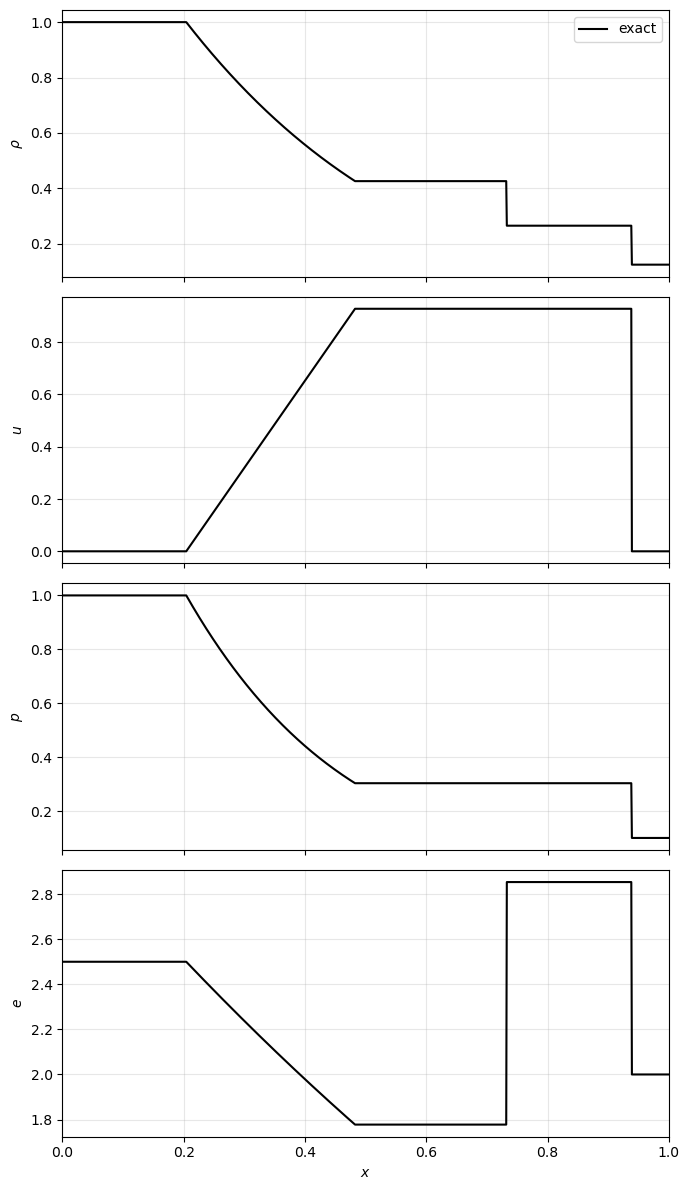

In [7]:
# The exact solution on its own
plot_sod([], tend)

## Part II. The CGF two-shock solver

The exact solver needs a Newton iteration with two different branches. The two-shock solver of Colella, Glaz and Ferguson assumes that both outer waves are shocks, so only the shock branch is ever used. The star pressure is still a root, but the function is smoother and cheaper, and sampling needs no fan.

For the Sod problem the left wave is really a rarefaction, so this is an approximation. Zingale's Fig. 8.7 shows how close the two curves stay near the crossing.

### 1. The solver:

In [8]:
def two_shock(qL, qR, gamma = 1.4, tol = 1.e-12):
    """
    Star pressure and velocity with both waves taken as shocks.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    def branch(p, rhoK, pK):
        """
        The shock branch of the pressure function, and its derivative.
        """

        AK = 2./((gamma + 1.)*rhoK)
        BK = (gamma - 1.)/(gamma + 1.)*pK

        f = (p - pK)*np.sqrt(AK/(p + BK))
        df = np.sqrt(AK/(BK + p))*(1. - 0.5*(p - pK)/(BK + p))

        return f, df

    p = max(tol, 0.5*(pL + pR))

    for it in range(50):

        fL, dfL = branch(p, rhoL, pL)
        fR, dfR = branch(p, rhoR, pR)

        p_new = max(tol, p - (fL + fR + uR - uL)/(dfL + dfR))

        if abs(p_new - p) < tol*p_new:
            p = p_new
            break

        p = p_new

    fL = branch(p, rhoL, pL)[0]
    fR = branch(p, rhoR, pR)[0]

    return p, 0.5*(uL + uR) + 0.5*(fR - fL)


def riemann_cgf(qL, qR, gamma = 1.4):
    """
    The state on the interface, xi = 0, from the two-shock solver.
    """

    rhoL, uL, pL = qL
    rhoR, uR, pR = qR

    cL = sound_speed(rhoL, pL, gamma)
    cR = sound_speed(rhoR, pR, gamma)

    ps, us = two_shock(qL, qR, gamma)

    # Densities behind each shock
    ratio = (gamma - 1.)/(gamma + 1.)
    rho_sL = rhoL*(ps/pL + ratio)/(ratio*ps/pL + 1.)
    rho_sR = rhoR*(ps/pR + ratio)/(ratio*ps/pR + 1.)

    # Speeds of the two outer waves
    SL = uL - cL*np.sqrt((gamma + 1.)/(2.*gamma)*ps/pL + (gamma - 1.)/(2.*gamma))
    SR = uR + cR*np.sqrt((gamma + 1.)/(2.*gamma)*ps/pR + (gamma - 1.)/(2.*gamma))

    # Which of the four states sits on the interface?
    if SL >= 0.:
        return rhoL, uL, pL

    if us >= 0.:
        return rho_sL, us, ps

    if SR >= 0.:
        return rho_sR, us, ps

    return rhoR, uR, pR

### 2. How good is the approximation?

qe compare the star state of the two solvers for Sod's data.

In [9]:
p_ex, u_ex = star_state(qL, qR, gamma)
p_ts, u_ts = two_shock(qL, qR, gamma)

print("exact      :  p* = %.6f   u* = %.6f" % (p_ex, u_ex))
print("two-shock  :  p* = %.6f   u* = %.6f" % (p_ts, u_ts))
print("difference :       %.2e        %.2e" % (abs(p_ts - p_ex), abs(u_ts - u_ex)))

exact      :  p* = 0.303130   u* = 0.927453
two-shock  :  p* = 0.303254   u* = 0.927837
difference :       1.24e-04        3.85e-04


## Part III. Finite-volume (FV) solver

### 1. Variables, fluxes and limiters:

The limiters are the ones we used for advection.

In [10]:
def primitive(U, gamma = 1.4):
    """
    From U = (rho, rho*u, E) to q = (rho, u, p).
    """

    rho = U[0]
    u = U[1]/rho
    p = (gamma - 1.)*(U[2] - 0.5*rho*u**2)

    return np.array([rho, u, p])


def conserved(q, gamma = 1.4):
    """
    From q = (rho, u, p) to U = (rho, rho*u, E).
    """

    rho, u, p = q

    return np.array([rho, rho*u, p/(gamma - 1.) + 0.5*rho*u**2])


def flux(q, gamma = 1.4):
    """
    The Euler flux, written in primitive variables.
    """

    rho, u, p = q
    E = p/(gamma - 1.) + 0.5*rho*u**2

    return np.array([rho*u, rho*u**2 + p, u*(E + p)])


def minmod(a, b):
    """
    The smaller slope, zero if the two disagree in sign.
    """

    if a*b <= 0.:
        return 0.

    return a if abs(a) < abs(b) else b


def slope(q, i, limiter = "mc"):
    """
    Limited slope of q in cell i, as an undivided difference.
    """

    dl = q[i] - q[i-1]
    dr = q[i+1] - q[i]
    dc = 0.5*(q[i+1] - q[i-1])

    if limiter == "minmod":
        return minmod(dl, dr)

    return minmod(minmod(2.*dl, 2.*dr), dc)

### 2. Parabolic reconstruction (PPM):

For PPM we interpolate the edge values with the fourth-order formula and then limit them so that the parabola stays monotonic inside the cell.

In [11]:
def ppm_edges(q, ilo, ihi):
    """
    Left and right edge values of the limited parabola in each cell.
    """

    n = len(q)
    qm = q.copy()
    qp = q.copy()

    # Fourth-order interpolant at the interfaces
    qint = np.zeros(n)
    for i in range(ilo - 1, ihi + 3):
        qint[i] = 7./12.*(q[i-1] + q[i]) - 1./12.*(q[i-2] + q[i+1])

    for i in range(ilo - 1, ihi + 2):
        qm[i] = qint[i]
        qp[i] = qint[i+1]

    # Limiting, as in the original PPM paper
    for i in range(ilo - 1, ihi + 2):

        if (qp[i] - q[i])*(q[i] - qm[i]) <= 0.:
            qm[i] = q[i]
            qp[i] = q[i]

        elif (qp[i] - qm[i])*(q[i] - 0.5*(qm[i] + qp[i])) > (qp[i] - qm[i])**2/6.:
            qm[i] = 3.*q[i] - 2.*qp[i]

        elif -(qp[i] - qm[i])**2/6. > (qp[i] - qm[i])*(q[i] - 0.5*(qm[i] + qp[i])):
            qp[i] = 3.*q[i] - 2.*qm[i]

    return qm, qp

### 3. The interface states:

Piecewise constant takes the cell averages themselves. The other two integrate under the reconstruction over the distance each wave travels in $\Delta t$, and keep only the waves moving towards the interface (Zingale, Eqs. 8.34 and 8.48):

$$q^{n+1/2}_{i+1/2,L} = \tilde{q}_+ - \sum_{\nu;\,\lambda^{(\nu)}\geq 0} \mathbf{l}^{(\nu)}\cdot\left[\tilde{q}_+ - \mathcal{I}^{(\nu)}_{+}(q)\right]\mathbf{r}^{(\nu)}$$

In [12]:
def interface_states(q, ilo, ihi, dx, dt, method = "godunov", limiter = "mc", gamma = 1.4):
    """
    Left and right primitive states at every interface.
    """

    n = q.shape[1]

    qL = np.zeros((3, n))
    qR = np.zeros((3, n))

    if method == "godunov":

        # Piecewise constant
        for i in range(ilo, ihi + 2):
            qL[:, i] = q[:, i-1]
            qR[:, i] = q[:, i]

        return qL, qR

    # Edge values of the parabola, only needed by ppm
    if method == "ppm":
        qm = np.zeros((3, n))
        qp = np.zeros((3, n))
        for k in range(3):
            qm[k], qp[k] = ppm_edges(q[k], ilo, ihi)

    for i in range(ilo - 1, ihi + 2):

        rho, u, p = q[:, i]
        c = sound_speed(rho, p, gamma)

        # The three waves
        lam = np.array([u - c, u, u + c])

        # Right eigenvectors, one per column, and left ones, one per row
        r = np.array([[1., 1., 1. ], [-c/rho, 0., c/rho], [c**2, 0., c**2 ]])

        l = np.array([[0., -rho/(2.*c), 1./(2.*c**2)], [1., 0., -1./c**2 ], [0., rho/(2.*c), 1./(2.*c**2)]])

        # Average of the reconstruction seen by each wave, Ip and Im
        Ip = np.zeros((3, 3))
        Im = np.zeros((3, 3))

        for nu in range(3):

            sigma = abs(lam[nu])*dt/dx

            if method == "plm":
                dq = np.array([slope(q[k], i, limiter) for k in range(3)])
                Ip[nu] = q[:, i] + 0.5*(1. - sigma)*dq
                Im[nu] = q[:, i] - 0.5*(1. - sigma)*dq

            else:
                dq = qp[:, i] - qm[:, i]
                q6 = 6.*(q[:, i] - 0.5*(qm[:, i] + qp[:, i]))
                Ip[nu] = qp[:, i] - 0.5*sigma*(dq - q6*(1. - 2./3.*sigma))
                Im[nu] = qm[:, i] + 0.5*sigma*(dq + q6*(1. - 2./3.*sigma))

        # Reference states: the fastest wave moving to each side
        ref_p = Ip[2] if lam[2] > 0. else q[:, i]
        ref_m = Im[0] if lam[0] < 0. else q[:, i]

        left = ref_p.copy()
        right = ref_m.copy()

        for nu in range(3):

            if lam[nu] >= 0.:
                left -= (l[nu] @ (ref_p - Ip[nu]))*r[:, nu]

            if lam[nu] <= 0.:
                right -= (l[nu] @ (ref_m - Im[nu]))*r[:, nu]

        qL[:, i+1] = left
        qR[:, i] = right

    # Keep density and pressure positive
    qL[0] = np.maximum(qL[0], 1.e-10)
    qL[2] = np.maximum(qL[2], 1.e-10)
    qR[0] = np.maximum(qR[0], 1.e-10)
    qR[2] = np.maximum(qR[2], 1.e-10)

    return qL, qR

### 4. The solver:

Fill the ghost cells, build the interface states, call the Riemann solver at every interface, and do the conservative update.

The timestep comes from the fastest wave on the grid, $\Delta t = C\,\Delta x/\max(|u| + c)$.

In [13]:
def solve_sod(nx, cfl = 0.8, method = "godunov", limiter = "mc", tend = 0.25, gamma = 1.4):
    """
    Finite-volume solution of the Sod problem on nx cells.
    """

    ng = 3
    ilo, ihi = ng, ng + nx - 1

    dx = 1./nx
    x = (np.arange(nx + 2*ng) - ng + 0.5)*dx

    # Initial data
    q = np.zeros((3, nx + 2*ng))
    q[:, x < x0] = np.array(qL)[:, None]
    q[:, x >= x0] = np.array(qR)[:, None]

    U = conserved(q, gamma)

    t = 0.

    while t < tend:

        # Outflow boundaries
        for k in range(ng):
            U[:, ilo - 1 - k] = U[:, ilo]
            U[:, ihi + 1 + k] = U[:, ihi]

        q = primitive(U, gamma)

        # Timestep from the fastest wave
        c = sound_speed(q[0], q[2], gamma)
        dt = cfl*dx/np.max(np.abs(q[1]) + c)

        if t + dt > tend:
            dt = tend - t

        # Reconstruct
        qLs, qRs = interface_states(q, ilo, ihi, dx, dt, method, limiter, gamma)

        # Solve the Riemann problem at each interface and build the flux
        F = np.zeros((3, nx + 2*ng))

        for i in range(ilo, ihi + 2):
            F[:, i] = flux(riemann_cgf(qLs[:, i], qRs[:, i], gamma), gamma)

        # Conservative update
        U[:, ilo:ihi+1] += dt/dx*(F[:, ilo:ihi+1] - F[:, ilo+1:ihi+2])

        t += dt

    return x[ilo:ihi+1], primitive(U, gamma)[:, ilo:ihi+1]

### 5. Comparing the three reconstructions:

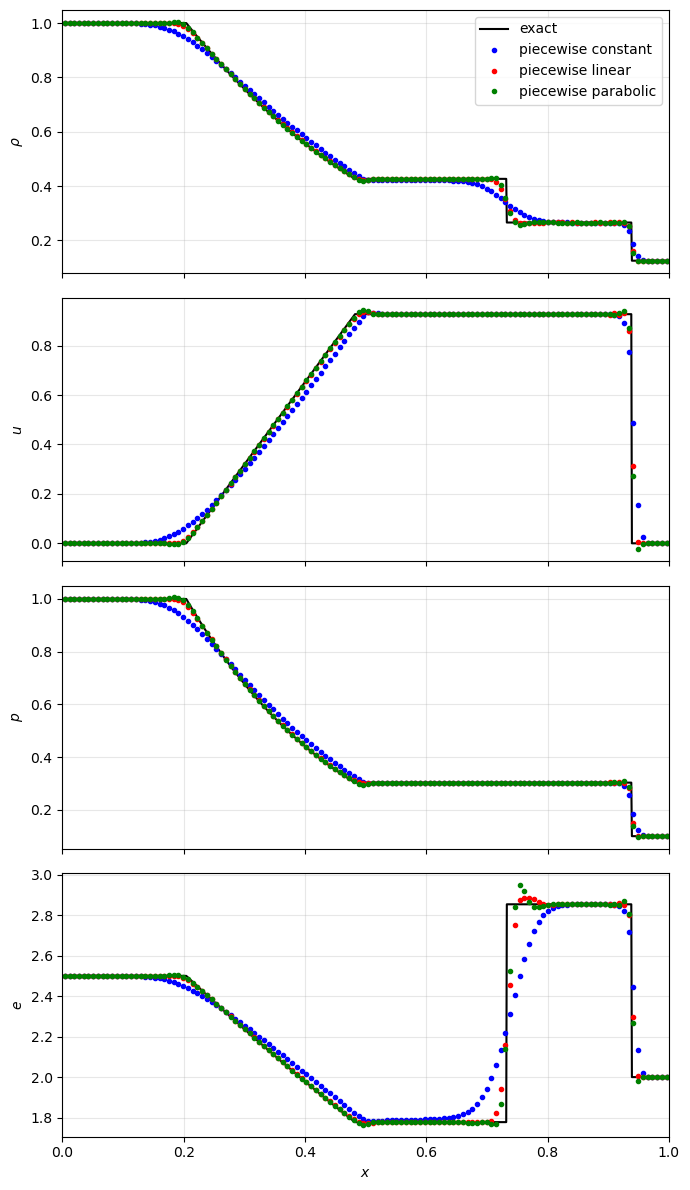

In [14]:
nx = 128

x_g, q_g = solve_sod(nx, method = "godunov", tend = tend)
x_l, q_l = solve_sod(nx, method = "plm", limiter = "mc", tend = tend)
x_p, q_p = solve_sod(nx, method = "ppm", tend = tend)

plot_sod([(x_g, q_g, "piecewise constant"), (x_l, q_l, "piecewise linear"), (x_p, q_p, "piecewise parabolic")], tend)